# Прогноз оттока клиентов: LightGBM (исходная модель) + 3 новые модели

**Что внутри**
1. Ваш исходный пайплайн (подготовка данных, таргет, признаки, разбиение по времени, LightGBM) — **без изменений**.
2. Общая функция оценки качества (в процентах).
3. Модель №1 — **Random Forest** (ансамблевый метод, *бэггинг*).
4. Модель №2 — **Логистическая регрессия** (линейный метод).
5. Модель №3 — **Дерево решений** (одиночное дерево, правила «если–то»).
6. Сводная таблица, графики и выбор лучшей модели.
7. тестировщик

Все модели обучаются на **тех же** train / valid / test, что и LightGBM, поэтому сравнение честное.

## 0. Исходный пайплайн

In [3]:
import polars as pl                      # основная библиотека для таблиц
import polars.selectors as cs            # «выбиралки» столбцов по типу (cs.numeric() и т.п.)
import numpy as np                       # массивы чисел, нужен для метрик
import lightgbm as lgb                   # градиентный бустинг (ансамбль деревьев)
from sklearn.metrics import roc_auc_score, average_precision_score

pl.Config.set_tbl_cols(-1)               # показывать ВСЕ столбцы таблиц (-1 = без ограничения)
pl.Config.set_tbl_rows(40)               # показывать до 40 строк

data_path = "../data/raw/"
df_clients = pl.read_csv(f"{data_path}clients.csv", try_parse_dates=True)          # справочник клиентов
df_monthly = pl.read_csv(f"{data_path}monthly_client.csv", try_parse_dates=True)   # главная таблица
df_nso     = pl.read_csv(f"{data_path}monthly_nso.csv", try_parse_dates=True)      # срочные вклады

df = (
    df_monthly
    .sort(["client_id", "report_date"])                  # порядок важен: сдвиги и скользящие окна
    .with_columns(
        pl.col("report_date").rank("dense").cast(pl.Int32).alias("month_idx")  # дата -> номер месяца 1..29
    )
)
max_idx = df["month_idx"].max()                          # последний месяц (29)
print(df.shape, "| клиентов:", df["client_id"].n_unique(), "| месяцев:", max_idx)

(87000, 70) | клиентов: 3000 | месяцев: 29


In [4]:
print(df.shape, "| клиентов:", df["client_id"].n_unique(), "| месяцев:", max_idx)
# Если строк меньше, чем клиентов × месяцев, кто-то «пропадает» из данных
print(df.group_by("client_id").len()["len"].value_counts().sort("len"))

(87000, 70) | клиентов: 3000 | месяцев: 29
shape: (1, 2)
┌─────┬───────┐
│ len ┆ count │
│ --- ┆ ---   │
│ u32 ┆ u32   │
╞═════╪═══════╡
│ 29  ┆ 3000  │
└─────┴───────┘


In [5]:
# 1. ОБЯЗАТЕЛЬНО: гарантируем правильный порядок строк (клиент -> хронология)
df = df.sort(["client_id", "month_idx"])

LIAB_DROP = 0.5   # пассивы упали ниже 50%
TXN_DROP  = 0.5   # транзакции упали ниже 50%

df = df.with_columns(
    # Пик по клиенту
    pl.col("total_liabilities_end").rolling_mean(3, min_samples=2)
      .cum_max().shift(1).over("client_id").alias("peak_liab"),
    pl.col("txn_cnt").cast(pl.Float64).rolling_mean(3, min_samples=2)
      .cum_max().shift(1).over("client_id").alias("peak_txn"),
).with_columns(
    # ИСПРАВЛЕНИЕ 1: используем "ИЛИ" (|) вместо "И" (&) — оттоком считается падение денег ИЛИ операций
    ((pl.col("total_liabilities_end") < LIAB_DROP * pl.col("peak_liab")) |
     (pl.col("txn_cnt") < TXN_DROP * pl.col("peak_txn"))).alias("is_low")
).with_columns(
    # Подтверждение падения
    (pl.col("is_low") & pl.col("is_low").shift(-1).over("client_id")).alias("is_low_confirmed")
).with_columns(
    pl.when(pl.col("is_low_confirmed")).then(pl.col("month_idx"))
      .min().over("client_id").alias("churn_idx_rule"),
    pl.col("month_idx").max().over("client_id").alias("last_idx"),
).with_columns(
    pl.min_horizontal(
        "churn_idx_rule",
        pl.when(pl.col("last_idx") < max_idx).then(pl.col("last_idx") + 1),
    ).alias("churn_idx")
).with_columns(
    pl.when(pl.col("month_idx") >= max_idx - 1).then(None)
      .when(pl.col("month_idx") + 1 == pl.col("churn_idx")).then(1)
      .otherwise(0)
      .cast(pl.Int8).alias("churn_next_month")
)

# Оставляем только строки с известным таргетом (убираем None) и до фактического ухода
df = df.filter(
    pl.col("churn_idx").is_null() | (pl.col("month_idx") < pl.col("churn_idx"))
)

print("Доля 1 по строкам (после исправления):", df["churn_next_month"].mean())

Доля 1 по строкам (после исправления): 0.015473458206855705


In [6]:
# НСО: агрегируем до уровня клиент + месяц
nso_agg = df_nso.group_by(["client_id", "report_date"]).agg(
    pl.col("early_close_flag").max().alias("nso_early_close_any"),
    pl.col("outflow_amt").sum().alias("nso_outflow_sum"),
)

df = (
    df.join(nso_agg, on=["client_id", "report_date"], how="left")
      .join(df_clients.select("client_id", "registration_date", "employee_cnt_start"),
            on="client_id", how="left")
      .sort(["client_id", "report_date"])          # join может сбить порядок, сортируем снова
      .with_columns(
          pl.col("nso_early_close_any", "nso_outflow_sum").fill_null(0),
          ((pl.col("report_date") - pl.col("registration_date")).dt.total_days() / 30.4)
              .alias("client_age_m"),
          pl.col("segment_name").replace_strict(
              {"MASS": 0, "Alfa Only": 1, "A-Club": 2}, default=-1),
      )
)

base_cols = ["total_liabilities_end", "demand_balance_avg", "nso_balance_avg", "txn_cnt",
             "txn_amt_in", "txn_amt_out", "active_days", "uniq_ca_cnt",
             "target_outflow_amt", "txn_oth_bank_amt", "salary_fund_amt"]

feat_exprs = []
for c in base_cols:
    x = pl.col(c).cast(pl.Float64)
    feat_exprs += [
        (x / (x.shift(1).over("client_id") + 1)).alias(f"{c}_chg_1m"),   # изменение к прошлому месяцу
        (x / (x.shift(3).over("client_id") + 1)).alias(f"{c}_chg_3m"),   # к 3 месяцам назад
        (x / (x.rolling_mean(6, min_samples=3).shift(1).over("client_id") + 1)).alias(f"{c}_vs_6m"),
        x.rolling_std(3, min_samples=2).over("client_id").alias(f"{c}_std_3m"),  # нестабильность
    ]

feat_exprs += [
    (pl.col("total_liabilities_end") / (pl.col("peak_liab") + 1)).alias("liab_vs_peak"),
    (pl.col("txn_cnt") / (pl.col("peak_txn") + 1)).alias("txn_vs_peak"),
    # сколько из последних 3 месяцев пассивы падали
    (pl.col("total_liabilities_end") < pl.col("total_liabilities_end").shift(1))
        .cast(pl.Int8).rolling_sum(3, min_samples=1).over("client_id").alias("liab_down_months_3m"),
]

df = df.with_columns(feat_exprs).with_columns(pl.col(pl.Boolean).cast(pl.Int8))

## Разбивка по времени

In [7]:
data = df.filter(pl.col("churn_next_month").is_not_null()).drop_nulls("peak_liab")

# при max_idx = 29: train ≤16 | зазор | valid 19–21 | зазор | test 24–27
train = data.filter(pl.col("month_idx") <= max_idx - 13)
valid = data.filter(pl.col("month_idx").is_between(max_idx - 10, max_idx - 8))
test  = data.filter(pl.col("month_idx").is_between(max_idx - 5,  max_idx - 2))

drop_cols = [
    "client_id", "report_date", "cpr_id", "month_idx", "registration_date",
    "churn_idx", "churn_idx_rule", "last_idx", "is_low_confirmed", 
    "is_low", "peak_liab", "peak_txn", "churn_next_month", 'target_outflow_amt'
]
features = [c for c in data.columns if c not in drop_cols and not c.startswith('target_outflow')]

for name, part in [("train", train), ("valid", valid), ("test", test)]:
    print(name, part.shape, "доля оттока:", round(part["churn_next_month"].mean(), 4))

train (37650, 130) доля оттока: 0.0153
valid (6766, 130) доля оттока: 0.0216
test (8114, 130) доля оттока: 0.0154


In [ ]:
import lightgbm as lgb
from sklearn.metrics import roc_auc_score, average_precision_score

X_tr, y_tr = train.select(features).to_pandas(), train["churn_next_month"].to_numpy()
X_va, y_va = valid.select(features).to_pandas(), valid["churn_next_month"].to_numpy()
X_te, y_te = test.select(features).to_pandas(),  test["churn_next_month"].to_numpy()

cat_features = ['segment_name', 'kp_id']
for col in cat_features:
    if col in X_tr.columns:
        X_tr[col] = X_tr[col].astype('category')
        X_va[col] = X_va[col].astype('category')
        X_te[col] = X_te[col].astype('category')

model = lgb.LGBMClassifier(
    n_estimators=1000,
    learning_rate=0.03,
    num_leaves=31,
    min_child_samples=50,
    subsample=0.8,
    subsample_freq=1,
    colsample_bytree=0.8,
    random_state=42,
    verbose=-1,
)
model.fit(
    X_tr, y_tr,
    eval_set=[(X_va, y_va)],
    eval_metric="auc",  # AUC гораздо стабильнее для early stopping
    categorical_feature=cat_features,
    callbacks=[lgb.early_stopping(50), lgb.log_evaluation(50)],
)


Training until validation scores don't improve for 50 rounds


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/lightgbm/sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


[50]	valid_0's auc: 0.861614	valid_0's binary_logloss: 0.0781724
Early stopping, best iteration is:
[47]	valid_0's auc: 0.862471	valid_0's binary_logloss: 0.0783554


,learning_rate,0.03
,n_estimators,1000
,min_child_samples,50
,subsample,0.8
,subsample_freq,1
,colsample_bytree,0.8
,random_state,42
,verbose,-1
,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1


In [9]:
p_te = model.predict_proba(X_te)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_te, p_te), 3))            # 0.5 = монетка, 1.0 = идеал
print("PR-AUC :", round(average_precision_score(y_te, p_te), 3))  # честнее при редком оттоке
print("Наивный бейзлайн (только liab_vs_peak):",
      round(roc_auc_score(y_te, -X_te["liab_vs_peak"]), 3))

# Бизнес-метрика: менеджеры обзванивают топ-10% клиентов с самым высоким риском
scored = test.select("client_id", "report_date", "churn_next_month").with_columns(
    pl.Series("score", p_te))
top = scored.sort("score", descending=True).head(int(0.1 * scored.height))
print("Recall@10%   :", round(top["churn_next_month"].sum() / scored["churn_next_month"].sum(), 3))
print("Precision@10%:", round(top["churn_next_month"].mean(), 3))

ROC-AUC: 0.906
PR-AUC : 0.507
Наивный бейзлайн (только liab_vs_peak): 0.659
Recall@10%   : 0.72
Precision@10%: 0.111


## 1. Как мы будем измерять «точность»

Отток редкий: в test ушло всего ~1.5 % клиентов. Поэтому обычная **Accuracy** (доля верных ответов) почти бесполезна:
модель «никто не уйдёт» получит ≈ 98.5 % и при этом не найдёт ни одного уходящего клиента.

Поэтому считаем набор метрик, все в **процентах**:

| Метрика | Что показывает |
|---|---|
| **ROC-AUC** | вероятность, что случайный уходящий клиент получит риск выше, чем случайный остающийся (качество *ранжирования*) |
| **PR-AUC** | то же, но чувствительно к редкому классу — главная метрика при дисбалансе |
| **Recall@10 %** | какую долю всех уходящих мы поймаем, если обзвонить топ-10 % самых рискованных (ваша бизнес-метрика) |
| **Precision@10 %** | какая доля из обзвоненных реально собиралась уйти |
| **Accuracy / Balanced accuracy / Precision / Recall / F1** | считаются при пороге, подобранном **на valid** (максимум F1), и применяются к test |

Порог подбирается на valid, а не на test — чтобы не «подглядывать» в тестовые данные.

In [10]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, precision_recall_curve)

results, probas = {}, {}     # сюда складываем метрики и вероятности каждой модели
rng = np.random.default_rng(42)

def evaluate(name, p_va, p_te):
    """Считает все метрики для модели и сохраняет их (в %)."""
    # 1) порог по максимуму F1 на VALID
    prec, rec, thr = precision_recall_curve(y_va, p_va)
    f1 = 2 * prec * rec / np.clip(prec + rec, 1e-12, None)
    t = thr[np.argmax(f1[:-1])]
    pred = (p_te >= t).astype(int)

    # 2) топ-10 % по риску (микро-шум разрывает «ничьи» у дерева, у которого много одинаковых вероятностей)
    k = int(0.1 * len(p_te))
    top = np.argsort(-(p_te + rng.uniform(0, 1e-9, len(p_te))))[:k]

    m = {
        "Accuracy":          accuracy_score(y_te, pred),
        "Balanced accuracy": balanced_accuracy_score(y_te, pred),
        "Precision":         precision_score(y_te, pred, zero_division=0),
        "Recall":            recall_score(y_te, pred),
        "F1":                f1_score(y_te, pred),
        "ROC-AUC":           roc_auc_score(y_te, p_te),
        "PR-AUC":            average_precision_score(y_te, p_te),
        "Recall@10%":        y_te[top].sum() / y_te.sum(),
        "Precision@10%":     y_te[top].mean(),
    }
    results[name] = {k_: round(100 * float(v), 2) for k_, v in m.items()}
    results[name]["Порог"] = round(float(t), 4)
    probas[name] = p_te
    return results[name]

print(f"Accuracy тривиальной модели «никто не уйдёт»: {100 * (1 - y_te.mean()):.2f} %  <- ориентир, который надо видеть")

Accuracy тривиальной модели «никто не уйдёт»: 98.46 %  <- ориентир, который надо видеть


### Исходная модель LightGBM — заносим в таблицу

Берём уже обученную `model` и считаем на ней те же метрики, чтобы сравнивать новые модели с ней на равных.

In [11]:
t0 = time.time()
evaluate("LightGBM (исходная)", model.predict_proba(X_va)[:, 1], model.predict_proba(X_te)[:, 1])
print(pd.Series(results["LightGBM (исходная)"]))

Accuracy             98.4600
Balanced accuracy    76.7700
Precision            50.0000
Recall               54.4000
F1                   52.1100
ROC-AUC              90.5800
PR-AUC               50.7100
Recall@10%           72.0000
Precision@10%        11.1000
Порог                 0.0808
dtype: float64


## 2. Подготовка данных для моделей scikit-learn

LightGBM умеет работать с пропусками (`NaN`) и категориями «из коробки». Модели sklearn — нет (логистическая регрессия точно), поэтому делаем явную подготовку:

1. **Бесконечности → NaN.** Признаки-отношения вида `x / (x_prev + 1)` могут дать `inf`, если `x_prev = -1`. Заменяем на пропуск.
2. **Пропуски → медиана** по train. Пропуски возникают в первых месяцах истории клиента (скользящие окна ещё не набрали данных). Медиана считается *только по train*, чтобы не было утечки из будущего.
3. **Категории** (`segment_name`, `kp_id`): для деревьев — `OrdinalEncoder` (номер категории: дерево само разрежет), для линейной модели — `OneHotEncoder` (иначе модель решит, что категория №5 «в 5 раз больше» №1). Редкие категории (< 30 наблюдений) склеиваются в одну.
4. **Только для логистической регрессии:** «знаковый логарифм» `sign(x)·log(1+|x|)` + стандартизация. Суммы денег и счётчики имеют тяжёлые хвосты (миллионы рядом с единицами); без этого один выброс «ломает» веса. Деревьям это не нужно — они зависят только от порядка значений, а не от масштаба.

In [12]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OrdinalEncoder, OneHotEncoder

num_cols = X_tr.select_dtypes(include=["number", "bool"]).columns.tolist()
cat_cols = [c for c in X_tr.columns if str(X_tr[c].dtype) in ("category", "object", "string")]
print(f"числовых признаков: {len(num_cols)} | категориальных: {len(cat_cols)} -> {cat_cols}")

def _inf_to_nan(a):
    a = np.asarray(a, dtype="float64").copy()
    a[~np.isfinite(a)] = np.nan
    return a

def _signed_log(a):
    return np.sign(a) * np.log1p(np.abs(a))

def _to_str(df):
    return pd.DataFrame(df).astype(str)

def make_preprocessor(kind):
    """kind='tree' -> для деревьев/леса; kind='linear' -> для логистической регрессии."""
    num_steps = [("inf", FunctionTransformer(_inf_to_nan, feature_names_out="one-to-one")),
                 ("imp", SimpleImputer(strategy="median"))]
    if kind == "linear":
        num_steps += [("log", FunctionTransformer(_signed_log, feature_names_out="one-to-one")),
                      ("sc",  StandardScaler())]
    cat_enc = (OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=30, sparse_output=False)
               if kind == "linear" else
               OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
    cat_steps = [("str", FunctionTransformer(_to_str, feature_names_out="one-to-one")), ("enc", cat_enc)]

    transformers = [("num", Pipeline(num_steps), num_cols)]
    if cat_cols:
        transformers.append(("cat", Pipeline(cat_steps), cat_cols))
    return ColumnTransformer(transformers, remainder="drop", verbose_feature_names_out=False)

print("Препроцессоры готовы.")

числовых признаков: 109 | категориальных: 2 -> ['kp_id', 'segment_name']
Препроцессоры готовы.


## 3. Модель №1 — Random Forest (ансамблевый метод)

**Как работает.** Random Forest — это *бэггинг*: строится сотни **независимых** глубоких деревьев, каждое на случайной подвыборке строк (bootstrap) и со случайным набором признаков при каждом разбиении. Итоговый риск — **среднее** вероятностей всех деревьев. Один глубокий лес переобучается на шум, но усреднение независимых ошибок сильно снижает дисперсию.

**Чем отличается от вашего LightGBM.** LightGBM — тоже ансамбль деревьев, но *бустинг*: деревья строятся **последовательно**, каждое исправляет ошибки предыдущих. Бустинг обычно точнее, лес — устойчивее и менее чувствителен к настройкам. Это хороший контраст двух ансамблевых стратегий.

**Что настраиваем.**
- `class_weight="balanced_subsample"` — редкий класс получает больший вес, иначе деревья «лениво» предсказывают «не уйдёт»;
- `min_samples_leaf` — минимальный размер листа: защита от переобучения (лист из 1–2 клиентов — это запоминание);
- `max_features` — сколько признаков рассматривается при разбиении (меньше → деревья разнообразнее).

Небольшой перебор делаем по **PR-AUC на valid**, test не трогаем до финальной оценки.

In [13]:
from sklearn.ensemble import RandomForestClassifier
from itertools import product

prep_tree = make_preprocessor("tree").fit(X_tr)
Xt_tr, Xt_va, Xt_te = (prep_tree.transform(X) for X in (X_tr, X_va, X_te))

best = {"score": -1}
t0 = time.time()
for leaf, mf in product([5, 20, 50], ["sqrt", 0.3]):
    rf = RandomForestClassifier(n_estimators=300, min_samples_leaf=leaf, max_features=mf,
                                class_weight="balanced_subsample", n_jobs=-1, random_state=42)
    rf.fit(Xt_tr, y_tr)
    s = average_precision_score(y_va, rf.predict_proba(Xt_va)[:, 1])
    print(f"min_samples_leaf={leaf:<3} max_features={mf!s:<5} -> PR-AUC(valid) = {s:.4f}")
    if s > best["score"]:
        best = {"score": s, "model": rf, "leaf": leaf, "mf": mf}
rf = best["model"]
print(f"\nЛучшие параметры: min_samples_leaf={best['leaf']}, max_features={best['mf']} | {time.time()-t0:.0f} c")

print(evaluate("Random Forest", rf.predict_proba(Xt_va)[:, 1], rf.predict_proba(Xt_te)[:, 1]))

min_samples_leaf=5   max_features=sqrt  -> PR-AUC(valid) = 0.3479
min_samples_leaf=5   max_features=0.3   -> PR-AUC(valid) = 0.3418
min_samples_leaf=20  max_features=sqrt  -> PR-AUC(valid) = 0.3323
min_samples_leaf=20  max_features=0.3   -> PR-AUC(valid) = 0.3331
min_samples_leaf=50  max_features=sqrt  -> PR-AUC(valid) = 0.3043
min_samples_leaf=50  max_features=0.3   -> PR-AUC(valid) = 0.3239

Лучшие параметры: min_samples_leaf=5, max_features=sqrt | 60 c
{'Accuracy': 98.51, 'Balanced accuracy': 76.41, 'Precision': 51.54, 'Recall': 53.6, 'F1': 52.55, 'ROC-AUC': 88.81, 'PR-AUC': 51.79, 'Recall@10%': 69.6, 'Precision@10%': 10.73, 'Порог': 0.2612}


**Какие признаки лес считает главными** (средний вклад в снижение неопределённости по всем деревьям):

In [14]:
names_tree = prep_tree.get_feature_names_out()
imp_rf = pd.Series(rf.feature_importances_, index=names_tree).sort_values(ascending=False)
print((imp_rf.head(15) * 100).round(2).to_string())

txn_amt_in_vs_6m          3.52
txn_amt_in_chg_3m         3.28
txn_self_amt              2.97
txn_vs_peak               2.80
op7_amt                   2.71
op7_cnt                   2.57
nso_balance_avg_chg_1m    2.49
txn_amt_in_chg_1m         2.29
txn_cnt                   2.25
txn_cnt_out               2.16
txn_cnt_in                1.95
nso_balance_avg_vs_6m     1.89
txn_cnt_vs_6m             1.84
active_days               1.76
txn_amt_out_vs_6m         1.63


## 4. Модель №2 — Логистическая регрессия (линейный метод)

**Как работает.** Модель считает взвешенную сумму признаков `z = w₁·x₁ + w₂·x₂ + … + b` и превращает её в вероятность формулой `p = 1 / (1 + e^(−z))`. Веса `w` подбираются так, чтобы минимизировать логарифмическую ошибку; штраф L2 (параметр `C`: меньше `C` → сильнее штраф) не даёт весам разрастаться на коррелирующих признаках — а у нас их много (`_chg_1m`, `_chg_3m`, `_vs_6m` одной и той же величины).

**Принципиальное отличие.** Модель **линейна**: каждый признак влияет на риск монотонно и независимо от остальных. Она не умеет «если операций мало И остаток упал — риск резко растёт». Зато она простая, быстрая, стабильная и полностью объяснима: знак и величина веса прямо говорят, как признак влияет на риск.

`class_weight="balanced"` — компенсируем редкость оттока. Перебираем `C` по PR-AUC на valid.

In [15]:
from sklearn.linear_model import LogisticRegression

prep_lin = make_preprocessor("linear").fit(X_tr)
Xl_tr, Xl_va, Xl_te = (prep_lin.transform(X) for X in (X_tr, X_va, X_te))

best = {"score": -1}
for C in [0.001, 0.01, 0.1, 1.0]:
    lr = LogisticRegression(C=C, class_weight="balanced", max_iter=3000, random_state=42)
    lr.fit(Xl_tr, y_tr)
    s = average_precision_score(y_va, lr.predict_proba(Xl_va)[:, 1])
    print(f"C={C:<6} -> PR-AUC(valid) = {s:.4f}")
    if s > best["score"]:
        best = {"score": s, "model": lr, "C": C}
lr = best["model"]
print(f"\nЛучший C = {best['C']}")

print(evaluate("Логистическая регрессия", lr.predict_proba(Xl_va)[:, 1], lr.predict_proba(Xl_te)[:, 1]))

C=0.001  -> PR-AUC(valid) = 0.1879
C=0.01   -> PR-AUC(valid) = 0.1977
C=0.1    -> PR-AUC(valid) = 0.1991
C=1.0    -> PR-AUC(valid) = 0.1969

Лучший C = 0.1
{'Accuracy': 98.18, 'Balanced accuracy': 71.51, 'Precision': 41.35, 'Recall': 44.0, 'F1': 42.64, 'ROC-AUC': 90.92, 'PR-AUC': 38.59, 'Recall@10%': 74.4, 'Precision@10%': 11.47, 'Порог': 0.8279}


**Что модель «думает»:** признаки с наибольшими по модулю весами (после стандартизации веса сопоставимы). Плюс — повышает риск ухода, минус — снижает.

In [16]:
names_lin = prep_lin.get_feature_names_out()
coef = pd.Series(lr.coef_[0], index=names_lin)
print("Сильнее всего ПОВЫШАЮТ риск:\n", coef.sort_values(ascending=False).head(8).round(3).to_string())
print("\nСильнее всего СНИЖАЮТ риск:\n", coef.sort_values().head(8).round(3).to_string())

Сильнее всего ПОВЫШАЮТ риск:
 employee_cnt_start                 1.958
total_liabilities_end_std_3m       0.701
nso_principal_outflow_amt          0.554
nso_outflow_sum                    0.554
salary_avg_payment_per_employee    0.528
txn_amt                            0.511
txn_amt_in                         0.475
salary_fund_amt_chg_3m             0.456

Сильнее всего СНИЖАЮТ риск:
 salary_employee_cnt         -1.139
amt_pd                      -0.855
demand_balance_avg_std_3m   -0.810
txn_cnt_out                 -0.654
salary_fund_amt_vs_6m       -0.620
txn_amt_in_vs_6m            -0.514
demand_balance_start        -0.420
txn_avg_amt                 -0.386


## 5. Модель №3 — Дерево решений (одиночное дерево)

**Как работает.** Одно дерево последовательно задаёт вопросы вида «`txn_vs_peak < 0.47`?», на каждом шаге выбирая признак и порог, которые лучше всего разделяют уходящих и остающихся (критерий Джини). Лист дерева выдаёт долю ушедших среди обучающих клиентов, попавших в него.

**Отличие от леса и бустинга.** Это «один эксперт» вместо «комитета». Плюс — дерево читается как набор правил, его можно показать бизнесу. Минус — высокая дисперсия: небольшое изменение данных меняет структуру, а глубокое дерево запоминает шум. Поэтому глубину (`max_depth`) и размер листа (`min_samples_leaf`) ограничиваем и подбираем по PR-AUC на valid.

**Особенность оценки.** Дерево выдаёт лишь несколько десятков разных вероятностей (по числу листьев), поэтому ранжирование клиентов у него грубее, чем у ансамблей.

In [17]:
from sklearn.tree import DecisionTreeClassifier, export_text

best = {"score": -1}
for depth, leaf in product([3, 5, 7, 10], [20, 50, 100]):
    dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf,
                                class_weight="balanced", random_state=42)
    dt.fit(Xt_tr, y_tr)
    s = average_precision_score(y_va, dt.predict_proba(Xt_va)[:, 1])
    print(f"max_depth={depth:<3} min_samples_leaf={leaf:<4} -> PR-AUC(valid) = {s:.4f}")
    if s > best["score"]:
        best = {"score": s, "model": dt, "depth": depth, "leaf": leaf}
dt = best["model"]
print(f"\nЛучшие параметры: max_depth={best['depth']}, min_samples_leaf={best['leaf']}")

print(evaluate("Дерево решений", dt.predict_proba(Xt_va)[:, 1], dt.predict_proba(Xt_te)[:, 1]))

max_depth=3   min_samples_leaf=20   -> PR-AUC(valid) = 0.1514
max_depth=3   min_samples_leaf=50   -> PR-AUC(valid) = 0.1495
max_depth=3   min_samples_leaf=100  -> PR-AUC(valid) = 0.2014
max_depth=5   min_samples_leaf=20   -> PR-AUC(valid) = 0.1628
max_depth=5   min_samples_leaf=50   -> PR-AUC(valid) = 0.2018
max_depth=5   min_samples_leaf=100  -> PR-AUC(valid) = 0.2350
max_depth=7   min_samples_leaf=20   -> PR-AUC(valid) = 0.2083
max_depth=7   min_samples_leaf=50   -> PR-AUC(valid) = 0.2316
max_depth=7   min_samples_leaf=100  -> PR-AUC(valid) = 0.2447
max_depth=10  min_samples_leaf=20   -> PR-AUC(valid) = 0.2104
max_depth=10  min_samples_leaf=50   -> PR-AUC(valid) = 0.2197
max_depth=10  min_samples_leaf=100  -> PR-AUC(valid) = 0.2394

Лучшие параметры: max_depth=7, min_samples_leaf=100
{'Accuracy': 98.37, 'Balanced accuracy': 69.25, 'Precision': 46.67, 'Recall': 39.2, 'F1': 42.61, 'ROC-AUC': 84.89, 'PR-AUC': 37.0, 'Recall@10%': 70.4, 'Precision@10%': 10.85, 'Порог': 0.947}


**Правила, которые выучило дерево** (верхние 3 уровня; `class: 1` — клиент уйдёт):

In [18]:
print(export_text(dt, feature_names=list(names_tree), max_depth=3))

|--- op7_amt <= 92.19
|   |--- txn_cnt_out <= 9.50
|   |   |--- txn_vs_peak <= 0.43
|   |   |   |--- txn_amt_out_chg_3m <= 1.22
|   |   |   |   |--- truncated branch of depth 2
|   |   |   |--- txn_amt_out_chg_3m >  1.22
|   |   |   |   |--- class: 0
|   |   |--- txn_vs_peak >  0.43
|   |   |   |--- txn_cnt <= 7.50
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- txn_cnt >  7.50
|   |   |   |   |--- truncated branch of depth 4
|   |--- txn_cnt_out >  9.50
|   |   |--- txn_amt_in_vs_6m <= 0.74
|   |   |   |--- nso_balance_avg_chg_1m <= 1.01
|   |   |   |   |--- truncated branch of depth 3
|   |   |   |--- nso_balance_avg_chg_1m >  1.01
|   |   |   |   |--- truncated branch of depth 3
|   |   |--- txn_amt_in_vs_6m >  0.74
|   |   |   |--- txn_int_amt <= 72753.52
|   |   |   |   |--- truncated branch of depth 4
|   |   |   |--- txn_int_amt >  72753.52
|   |   |   |   |--- truncated branch of depth 4
|--- op7_amt >  92.19
|   |--- txn_vs_peak <= 0.46
|   |   |--- class: 0


## 6. Сводная таблица и выбор лучшей модели

Таблица ниже — **итоговые проценты на test** (данные, которые ни одна модель не видела при обучении и подборе параметров).

In [19]:
cols = ["Accuracy", "Balanced accuracy", "Precision", "Recall", "F1",
        "ROC-AUC", "PR-AUC", "Recall@10%", "Precision@10%"]
summary = pd.DataFrame(results).T[cols + ["Порог"]]
pd.set_option("display.width", 200)
print("Значения в %, test-выборка\n")
print(summary.sort_values("PR-AUC", ascending=False).to_string())

Значения в %, test-выборка

                         Accuracy  Balanced accuracy  Precision  Recall     F1  ROC-AUC  PR-AUC  Recall@10%  Precision@10%   Порог
Random Forest               98.51              76.41      51.54    53.6  52.55    88.81   51.79        69.6          10.73  0.2612
LightGBM (исходная)         98.46              76.77      50.00    54.4  52.11    90.58   50.71        72.0          11.10  0.0808
Логистическая регрессия     98.18              71.51      41.35    44.0  42.64    90.92   38.59        74.4          11.47  0.8279
Дерево решений              98.37              69.25      46.67    39.2  42.61    84.89   37.00        70.4          10.85  0.9470


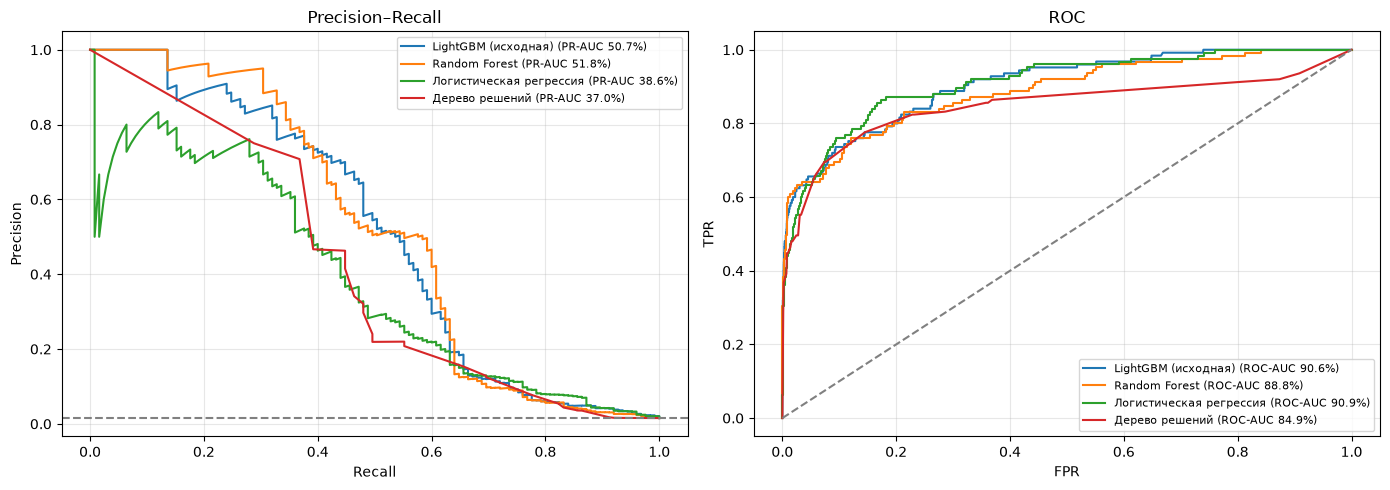

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
from sklearn.metrics import roc_curve
for name, p in probas.items():
    pr, rc, _ = precision_recall_curve(y_te, p)
    ax[0].plot(rc, pr, label=f"{name} (PR-AUC {results[name]['PR-AUC']:.1f}%)")
    fpr, tpr, _ = roc_curve(y_te, p)
    ax[1].plot(fpr, tpr, label=f"{name} (ROC-AUC {results[name]['ROC-AUC']:.1f}%)")
ax[0].axhline(y_te.mean(), ls="--", c="gray"); ax[0].set(title="Precision–Recall", xlabel="Recall", ylabel="Precision")
ax[1].plot([0, 1], [0, 1], ls="--", c="gray");  ax[1].set(title="ROC", xlabel="FPR", ylabel="TPR")
for a in ax: a.legend(fontsize=8); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [21]:
# Выбор лучшей модели: главный критерий — PR-AUC (честная метрика при редком оттоке),
# при близких значениях решают ROC-AUC и Recall@10 % (бизнес-метрика).
rank = summary[["PR-AUC", "ROC-AUC", "Recall@10%"]].rank(ascending=False).mean(axis=1)
best_name = summary["PR-AUC"].idxmax()
print("Средний ранг по PR-AUC / ROC-AUC / Recall@10%:")
print(rank.sort_values().round(2).to_string())
print(f"\n>>> ЛУЧШАЯ МОДЕЛЬ по PR-AUC: {best_name}")
print(summary.loc[best_name, ["ROC-AUC", "PR-AUC", "Recall@10%", "Precision@10%", "Accuracy"]].to_string())

Средний ранг по PR-AUC / ROC-AUC / Recall@10%:
Логистическая регрессия    1.67
LightGBM (исходная)        2.00
Random Forest              2.67
Дерево решений             3.67

>>> ЛУЧШАЯ МОДЕЛЬ по PR-AUC: Random Forest
ROC-AUC          88.81
PR-AUC           51.79
Recall@10%       69.60
Precision@10%    10.73
Accuracy         98.51


### Как читать результат и обосновать выбор

- **Accuracy не критерий.** У всех моделей она будет выглядеть высокой/разной из-за порога и дисбаланса; смотрите на PR-AUC, Recall@10 % и Balanced accuracy.
- **Если лидирует LightGBM / Random Forest** — значит, отток определяется *взаимодействием* признаков (падение операций + падение остатков + досрочное закрытие НСО одновременно), а такое ловят только ансамбли деревьев; линейная модель этого не видит.
  Бустинг обычно впереди леса: он последовательно «дожимает» трудные случаи (редкие уходящие клиенты), а лес лишь усредняет независимые деревья.
- **Если близко к ним Логистическая регрессия** — значит, сигнал в основном простой и монотонный (чем сильнее падение, тем выше риск); тогда её простота и объяснимость — аргумент в её пользу.
- **Дерево решений** почти всегда будет последним по ранжированию (мало разных вероятностей, высокая дисперсия), но самым понятным для бизнеса: его правила можно прочитать в ячейке выше.
- Разница в 1–2 п.п. при ~120 уходящих клиентах в test лежит в пределах статистического шума — для окончательного решения полезно повторить оценку на нескольких временных окнах.